## FinTrust Week 2 — Python Exploratory Data Analysis #

**Track:** Data Analytics - **George C. Oluoch**

**Data used:** Clean_Transactions.csv and Clean_Customers.csv (cleaned, Part A)

**Note:** Risk_Review_Flag is a synthetic label and is not a real fraud determination.

This notebook investigates customer segments, transaction types, transaction amounts,
transaction channels, transaction status, international transactions, customer behaviour,
and risk-review patterns, through five visualisations built with Pandas, NumPy, Matplotlib,
and Seaborn.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Load Data
customers = pd.read_csv("C:/Users/USER/Documents/AnalystLab Africa/FinTrust_Bank/Fintrust_Data - Clean_Customers.csv")
transactions = pd.read_csv("C:/Users/USER/Documents/AnalystLab Africa/FinTrust_Bank/Fintrust_Data - Clean_Transactions.csv")

In [33]:
customers.head(15)

,Customer_ID,Customer_Name,Age,Gender,City,Customer_Segment,Account_Type,Tenure_Months,Digital_Engagement_Score,Monthly_Income_Band,Preferred_Channel,Account_Status
0,FT-C00001,Ibrahim Adeyemi,56,Male,Lagos,Premium,Savings,55,16.7,500k-999k,Mobile App,Active
1,FT-C00002,Yusuf Mohammed,46,Male,Kano,Everyday,Current,79,17.1,500k-999k,Mobile App,Active
2,FT-C00003,Emeka Adeyemi,32,Female,Port Harcourt,Everyday,Savings,43,17.3,1m+,Mobile App,Active
3,FT-C00004,David Williams,60,Female,Benin City,Premium,Premium,44,18.0,500k-999k,Mobile App,Dormant
4,FT-C00005,Blessing Adeyemi,25,Male,Kaduna,Premium,Savings,68,19.3,500k-999k,Mobile App,Active
5,FT-C00006,Samuel Eze,38,Male,Lagos,Everyday,Savings,33,19.6,500k-999k,Mobile App,Active
6,FT-C00007,Tunde Williams,56,Male,Kaduna,Everyday,Savings,24,19.6,Below 100k,Mobile App,Active
7,FT-C00008,Yusuf Eze,36,Female,Lagos,SME,Savings,36,21.4,100k-249k,USSD,Active
8,FT-C00009,Samuel Mohammed,40,Male,Lagos,Everyday,Premium,10,22.2,500k-999k,Web,Active
9,FT-C00010,Blessing Usman,28,Male,Lagos,Everyday,Savings,20,23.2,250k-499k,Mobile App,Active


In [6]:
transactions = transactions.drop(columns=["Transaction_DateTime"])

KeyError: "['Transaction_DateTime'] not found in axis"

In [10]:
transactions["Transaction_Date_Clean"] = pd.to_datetime(
    transactions["Transaction_Date_Clean"], dayfirst=True
)
print(transactions["Transaction_Date_Clean"].dtype)
print(transactions["Transaction_Date_Clean"].min())
print(transactions["Transaction_Date_Clean"].max())

datetime64[ns]
2026-01-01 00:00:00
2026-03-31 23:59:00


In [32]:
transactions.head(15)

,Transaction_ID,Customer_ID,Transaction_Type,Amount_NGN,Channel,Device_Type,Location,International_Transaction,Transaction_Status,Risk_Review_Flag,Transaction_Date_Clean
0,FT-T000001,FT-C01135,Card Purchase,5923.80,Mobile App,Android,Enugu,No,Reversed,Yes,2026-01-01 00:00:00
1,FT-T000002,FT-C00428,Cash Withdrawal,11681.12,ATM,Android,Kaduna,No,Successful,Yes,2026-01-01 00:10:00
2,FT-T000003,FT-C00469,Transfer,571.91,ATM,POS Terminal,Kano,No,Successful,No,2026-01-01 00:21:00
3,FT-T000004,FT-C01015,Deposit,105367.52,Mobile App,Web Browser,Abuja,No,Successful,No,2026-01-01 00:32:00
4,FT-T000005,FT-C00870,Cash Withdrawal,3049.06,Mobile App,POS Terminal,Abuja,No,Successful,No,2026-01-01 00:43:00
5,FT-T000006,FT-C00770,Airtime/Data,175.89,POS,Android,Port Harcourt,No,Successful,No,2026-01-01 00:54:00
6,FT-T000007,FT-C00680,Airtime/Data,18733.61,Mobile App,Android,Lagos,No,Successful,No,2026-01-01 01:04:00
7,FT-T000008,FT-C00805,Card Purchase,6702.14,Web,Android,Kaduna,No,Successful,No,2026-01-01 01:15:00
8,FT-T000009,FT-C00886,Airtime/Data,10503.84,POS,ATM Terminal,Ibadan,No,Successful,No,2026-01-01 01:26:00
9,FT-T000010,FT-C00561,Airtime/Data,16528.85,Mobile App,ATM Terminal,Benin City,No,Successful,Yes,2026-01-01 01:37:00


In [12]:
print(customers.shape)
print(transactions.shape)
print(transactions.columns.tolist())

(1500, 12)
(12000, 11)
['Transaction_ID', 'Customer_ID', 'Transaction_Type', 'Amount_NGN', 'Channel', 'Device_Type', 'Location', 'International_Transaction', 'Transaction_Status', 'Risk_Review_Flag', 'Transaction_Date_Clean']


# Deep Dive - EDA


## Chart 1: Transaction Volume by Channel

**What the visual shows:**

The number of transactions processed through each of FinTrust's five channels — Mobile App,
POS, Web, ATM, and USSD — ordered from busiest to quietest.

**Why is it important?**

Channel volume shows where FinTrust's digital infrastructure carries the most load and where
customers actually choose to transact, rather than where activity might be assumed to concentrate.

**Business insight derived drom it**

Mobile App accounts for close to half of all transaction volume **(about 43%)**, more than double
the next channel. Mobile App reliability, performance, and support capacity therefore matter
disproportionately to the overall customer experience, and future digital investment should be
weighted toward mobile first.

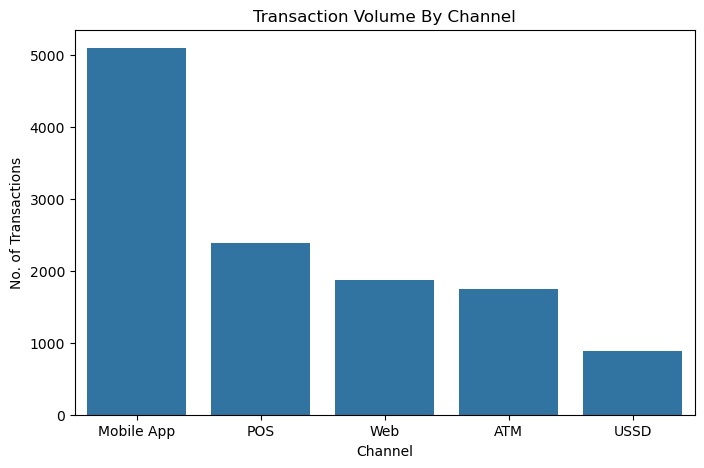

In [16]:
# Chart 1: Transaction Volume by Channel
plt.figure(figsize=(8,5))
sns.countplot(data=transactions, x="Channel", order=transactions["Channel"].value_counts().index)
plt.title("Transaction Volume By Channel")
plt.xlabel("Channel")
plt.ylabel("No. of Transactions")
plt.show()

## Chart 2: Transaction Status Breakdown

**What the visual shows:**

The proportion of all 12,000 transactions that are Successful, Failed, Reversed, or Pending.

**Why is it important?**

This is the clearest single measure of operational health, showing what share of transactions
complete without issue versus what share require attention.

**Business insight derived drom it**

While **90.5%** of transactions succeed, roughly 1 in 10 do not, split across Failed **(5.2%)**,
Reversed **(2.7%)**, and Pending **(1.6%)**. At current volume, this represents over **1,100** transactions
a quarter needing follow-up, exactly the situations the approved Knowledge Base addresses.
Even a small improvement in failure and reversal rates would meaningfully improve the customer
experience at scale.

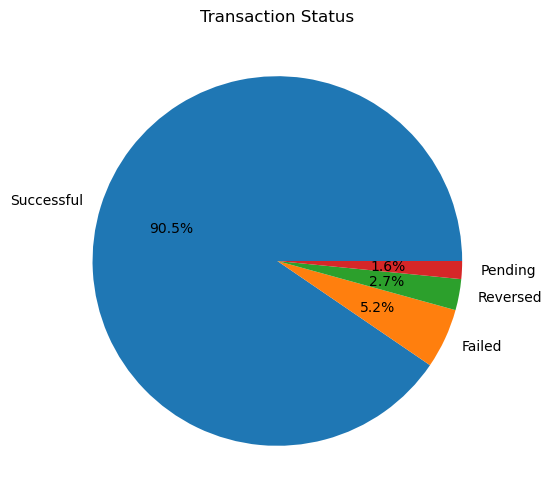

In [21]:
#Chart 2: Transaction Status Breakdown
plt.figure(figsize=(6,6))
transactions["Transaction_Status"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Transaction Status")
plt.ylabel("")
plt.show()

## Chart 3: Transaction Amount Distribution by Risk Review Flag

**What the visual shows:**

The spread of transaction amounts (NGN), compared between transactions flagged for risk review
and those not flagged, including the median, the middle **50** of values, and outliers.

**Why is it important?**

This tests whether transaction amount alone is a useful signal for the risk-review flag, which
is directly relevant to future risk-scoring work.

**Business insight derived from it:**

Flagged transactions have a higher median value **(NGN 13,541)** than unflagged transactions
**(NGN 9,591)**, about **41%** higher. However, the overall spread and the presence of high-value
outliers are broadly similar between the two groups, hence amount alone is a partial signal, not
a strong one. A monitoring rule based purely on "amount above X" would likely produce many
false positives.

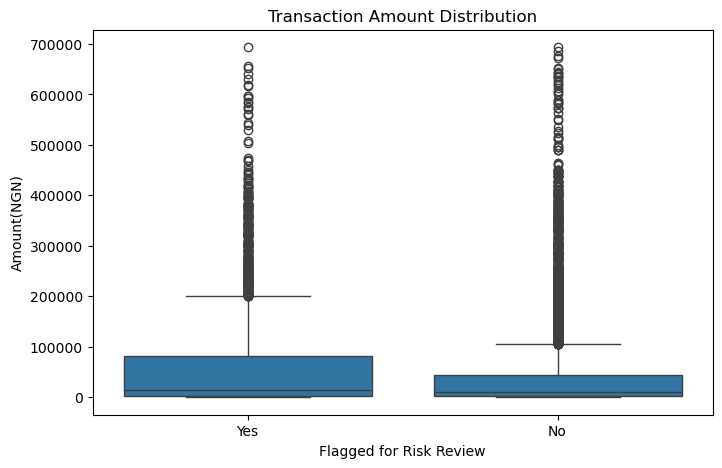

Median amount, flagged: 13541.130000000001
Median amount, unflagged: 9591.115


In [27]:
# Chart 3: Transaction Amount Distribution, split by Risk Flag
plt.figure(figsize=(8,5))
sns.boxplot(data=transactions, x="Risk_Review_Flag", y="Amount_NGN")
plt.title("Transaction Amount Distribution")
plt.xlabel("Flagged for Risk Review")
plt.ylabel("Amount(NGN)")
plt.show()
            
median_flagged = np.median(transactions.loc[transactions["Risk_Review_Flag"] == "Yes", "Amount_NGN"])
median_unflagged = np.median(transactions.loc[transactions["Risk_Review_Flag"] == "No", "Amount_NGN"])
print("Median amount, flagged:", median_flagged)
print("Median amount, unflagged:", median_unflagged)

## Chart 4: Median Transaction Value by Customer Segment

**What the visual shows:**

The typical (median) transaction value for customers in each of FinTrust's four segments:
Everyday, Premium, Student, and SME.

**Why is it important?**

This tests whether segment membership predicts transaction size, which is relevant to whether
FinTrust's segment labels reflect real behavioural differences.

**Business insight derived from it:**

**SME customers** show the highest typical transaction value (around **NGN 11,500–12,000**), consistent
with business-related transactions tending to be larger. Notably, **Premium customers** do not have
the highest median value; they rank third, below both **SME and Student**. This suggests the Premium
label may reflect a different criterion, such as tenure or income band, rather than transaction
size, and product decisions should not assume Premium customers are the bank's highest-value
transactors by amount alone.

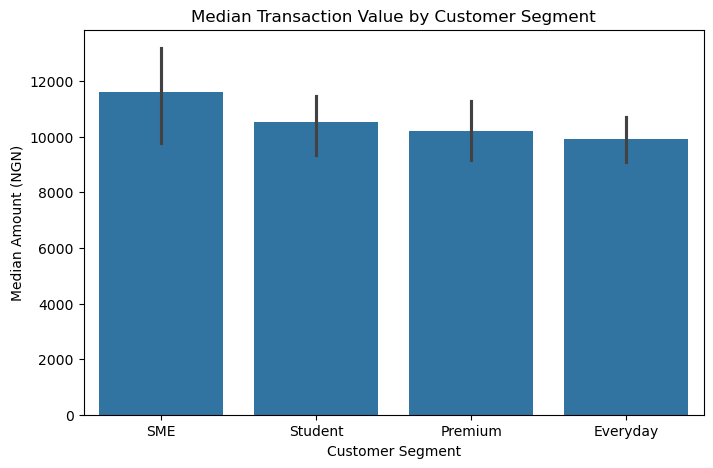

In [34]:
# Chart 4: Median Transaction Value by Customer Segment
merged = transactions.merge(customers, on="Customer_ID", how="left")

plt.figure(figsize=(8,5))
sns.barplot(data=merged, x="Customer_Segment", y="Amount_NGN", estimator=np.median,
            order=merged.groupby("Customer_Segment")["Amount_NGN"].median().sort_values(ascending=False).index)
plt.title("Median Transaction Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Median Amount (NGN)")
plt.show()

## Chart 5: Risk Review Flag Rate — International vs Domestic

**What the visual show:**

The percentage of transactions flagged for risk review, split by whether the transaction was
domestic or international.

**Why is it important?**

This tests one of the clearest hypotheses about risk patterns: whether crossing a border
correlates with a higher review-flag rate.

**What business insight can be derived from it?**

International transactions are flagged at **36.9%**, almost double the domestic rate of **18.9%**.
Combined with international transactions making up only **4%** of total volume (Week 1 profiling),
this means international transactions are a small share of activity but a disproportionately
large share of risk-review workload. This is a stronger candidate signal than transaction
amount, and is useful both for the risk team's capacity planning and as a feature for future
risk modelling.

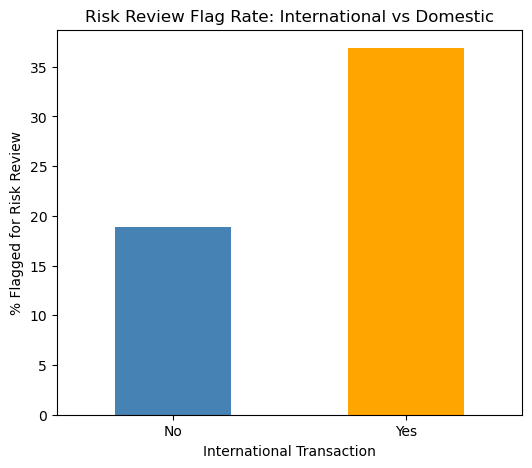

International_Transaction
No     18.880208
Yes    36.875000
Name: Risk_Review_Flag, dtype: float64


In [35]:
# Chart 5: International vs Domestic, Risk-Flag Rate
flag_rate = transactions.groupby("International_Transaction")["Risk_Review_Flag"].apply(
    lambda x: (x == "Yes").mean() * 100
)

plt.figure(figsize=(6,5))
flag_rate.plot(kind="bar", color=["steelblue", "orange"])
plt.title("Risk Review Flag Rate: International vs Domestic")
plt.xlabel("International Transaction")
plt.ylabel("% Flagged for Risk Review")
plt.xticks(rotation=0)
plt.show()

print(flag_rate)

## Summary

Across five visualisations, three findings stand out as most actionable for FinTrust:

1. **Mobile App** carries the largest share of **transaction volume** and deserves priority in
   reliability and support planning.
2. About **1 in 10** transactions do not complete successfully, representing a concrete
   operational improvement target.
3. **International status** is a stronger indicator of risk-review flagging than **transaction
   amount**, and should be treated as a priority signal in future risk-related work.

All findings are based on synthetic FinTrust data. Risk_Review_Flag reflects a synthetic
label and is not a real fraud determination.